In [2]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

In [3]:
df=pd.read_csv(r"C:\Users\ACCURATE\Desktop\Data Science\DataSets\artificial\Amazon Fine Food Reviews.csv")
df

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
568449,568450,B001EO7N10,A28KG5XORO54AY,Lettie D. Carter,0,0,5,1299628800,Will not do without,Great for sesame chicken..this is a good if no...
568450,568451,B003S1WTCU,A3I8AFVPEE8KI5,R. Sawyer,0,0,2,1331251200,disappointed,I'm disappointed with the flavor. The chocolat...
568451,568452,B004I613EE,A121AA1GQV751Z,"pksd ""pk_007""",2,2,5,1329782400,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
568452,568453,B004I613EE,A3IBEVCTXKNOH,"Kathy A. Welch ""katwel""",1,1,5,1331596800,Favorite Training and reward treat,These are the BEST treats for training and rew...


## DATA UNDERSTANDING

In [4]:
#first 5 rows
print(df.head())

   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3   4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4   5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   
3                     3                       3      2  1307923200   
4                     0                       0      5  1350777600   

                 Summary                                               Text  
0  Good Quality Dog Food  I have bought several of the Vitality canned d...  
1 

In [5]:
#last 5 rows
print(df.tail())

            Id   ProductId          UserId              ProfileName  \
568449  568450  B001EO7N10  A28KG5XORO54AY         Lettie D. Carter   
568450  568451  B003S1WTCU  A3I8AFVPEE8KI5                R. Sawyer   
568451  568452  B004I613EE  A121AA1GQV751Z            pksd "pk_007"   
568452  568453  B004I613EE   A3IBEVCTXKNOH  Kathy A. Welch "katwel"   
568453  568454  B001LR2CU2  A3LGQPJCZVL9UC                 srfell17   

        HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
568449                     0                       0      5  1299628800   
568450                     0                       0      2  1331251200   
568451                     2                       2      5  1329782400   
568452                     1                       1      5  1331596800   
568453                     0                       0      5  1338422400   

                                   Summary  \
568449                 Will not do without   
568450                        

In [6]:
#no of rows and columns
print(df.shape)

(568454, 10)


In [7]:
#statistical summary of numerical columns
print(df.describe())

                  Id  HelpfulnessNumerator  HelpfulnessDenominator  \
count  568454.000000         568454.000000            568454.00000   
mean   284227.500000              1.743817                 2.22881   
std    164098.679298              7.636513                 8.28974   
min         1.000000              0.000000                 0.00000   
25%    142114.250000              0.000000                 0.00000   
50%    284227.500000              0.000000                 1.00000   
75%    426340.750000              2.000000                 2.00000   
max    568454.000000            866.000000               923.00000   

               Score          Time  
count  568454.000000  5.684540e+05  
mean        4.183199  1.296257e+09  
std         1.310436  4.804331e+07  
min         1.000000  9.393408e+08  
25%         4.000000  1.271290e+09  
50%         5.000000  1.311120e+09  
75%         5.000000  1.332720e+09  
max         5.000000  1.351210e+09  


In [8]:
#statistical summary of categorical and text columns
print(df.describe(include=object))

C:\Users\ACCURATE\AppData\Local\Temp\ipykernel_19772\2384902051.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include=object))


         ProductId          UserId       ProfileName     Summary  \
count       568454          568454            568428      568427   
unique       74258          256059            218415      295742   
top     B007JFMH8M  A3OXHLG6DIBRW8  C. F. Hill "CFH"  Delicious!   
freq           913             448               451        2462   

                                                     Text  
count                                              568454  
unique                                             393579  
top     This review will make me sound really stupid, ...  
freq                                                  199  


In [9]:
#informations
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB
None


In [10]:
#column names
print(df.columns)

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='str')


In [11]:
#number of unique values in each column
print(df.nunique())

Id                        568454
ProductId                  74258
UserId                    256059
ProfileName               218415
HelpfulnessNumerator         231
HelpfulnessDenominator       234
Score                          5
Time                        3168
Summary                   295742
Text                      393579
dtype: int64


In [12]:
#datatypes
print(df.dtypes)

Id                        int64
ProductId                   str
UserId                      str
ProfileName                 str
HelpfulnessNumerator      int64
HelpfulnessDenominator    int64
Score                     int64
Time                      int64
Summary                     str
Text                        str
dtype: object


In [13]:
#target column
print(df['Score'].value_counts())

Score
5    363122
4     80655
1     52268
3     42640
2     29769
Name: count, dtype: int64


## DATA CLEANING

In [14]:
#DUPLICATE VALUES
print(df.duplicated().sum())

0


In [15]:
#REMOVING COLUMNS THAT OUPUT DOESN'T DEPEND ON
df=df.drop(['Id','ProductId','UserId','ProfileName','HelpfulnessNumerator','HelpfulnessDenominator','Time'],axis=1)

In [16]:
#MISSING VALUE
print(df.isnull().sum())

Score       0
Summary    27
Text        0
dtype: int64


In [17]:
#HANDLING MISSING VALUES
df['Summary']=df['Summary'].fillna('')
print(df.isnull().sum())

Score      0
Summary    0
Text       0
dtype: int64


In [18]:
#TEXT COLUMN AND SUMMARY COLUMN CAN BE COMBINED
df["review"] = df["Summary"] + " " + df["Text"]
df=df.drop(['Summary','Text'],axis=1)
df

,Score,review
0,5,Good Quality Dog Food I have bought several of...
1,1,Not as Advertised Product arrived labeled as J...
2,4,"""Delight"" says it all This is a confection tha..."
3,2,Cough Medicine If you are looking for the secr...
4,5,Great taffy Great taffy at a great price. The...
...,...,...
568449,5,Will not do without Great for sesame chicken.....
568450,2,disappointed I'm disappointed with the flavor....
568451,5,Perfect for our maltipoo These stars are small...
568452,5,Favorite Training and reward treat These are t...


In [19]:
#MAPPING SCORES TO NEGATIVE,NEUTRAL AND POSITIVE
df['Score']=df['Score'].map({1:0,2:0,3:1,4:2,5:2})
label_names = {0: "negative", 1: "neutral", 2: "positive"}
print(df['Score'].value_counts())
df

Score
2    443777
0     82037
1     42640
Name: count, dtype: int64


,Score,review
0,2,Good Quality Dog Food I have bought several of...
1,0,Not as Advertised Product arrived labeled as J...
2,2,"""Delight"" says it all This is a confection tha..."
3,0,Cough Medicine If you are looking for the secr...
4,2,Great taffy Great taffy at a great price. The...
...,...,...
568449,2,Will not do without Great for sesame chicken.....
568450,0,disappointed I'm disappointed with the flavor....
568451,2,Perfect for our maltipoo These stars are small...
568452,2,Favorite Training and reward treat These are t...


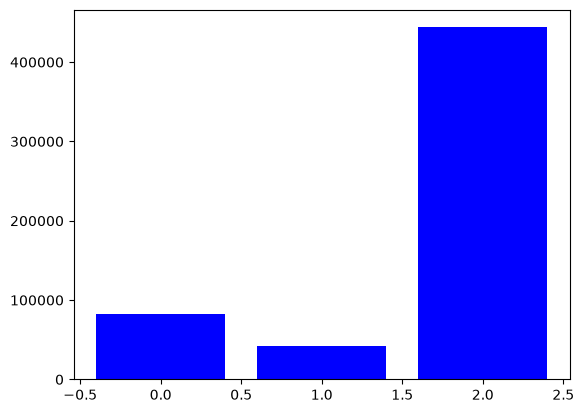

In [20]:
#TARGET COLUMN BARPLOT
xlab=df['Score'].unique()
ylab=df['Score'].value_counts()
plt.bar(xlab,ylab,color='blue')
plt.show()

In [21]:
#defining text column
text=df['review']
text

0         Good Quality Dog Food I have bought several of...
1         Not as Advertised Product arrived labeled as J...
2         "Delight" says it all This is a confection tha...
3         Cough Medicine If you are looking for the secr...
4         Great taffy Great taffy at a great price.  The...
                                ...                        
568449    Will not do without Great for sesame chicken.....
568450    disappointed I'm disappointed with the flavor....
568451    Perfect for our maltipoo These stars are small...
568452    Favorite Training and reward treat These are t...
568453    Great Honey I am very satisfied ,product is as...
Name: review, Length: 568454, dtype: str

In [22]:
#TOKENIZATION
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
text = text.apply(lambda x: ' '.join(word_tokenize(x, preserve_line=True)))
text

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ACCURATE\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


0         Good Quality Dog Food I have bought several of...
1         Not as Advertised Product arrived labeled as J...
2         `` Delight '' says it all This is a confection...
3         Cough Medicine If you are looking for the secr...
4         Great taffy Great taffy at a great price. Ther...
                                ...                        
568449    Will not do without Great for sesame chicken ....
568450    disappointed I 'm disappointed with the flavor...
568451    Perfect for our maltipoo These stars are small...
568452    Favorite Training and reward treat These are t...
568453    Great Honey I am very satisfied , product is a...
Name: review, Length: 568454, dtype: str

In [23]:
#removing html tags
text = text.replace('<[^>]+>', " ", regex=True)
text

0         Good Quality Dog Food I have bought several of...
1         Not as Advertised Product arrived labeled as J...
2         `` Delight '' says it all This is a confection...
3         Cough Medicine If you are looking for the secr...
4         Great taffy Great taffy at a great price. Ther...
                                ...                        
568449    Will not do without Great for sesame chicken ....
568450    disappointed I 'm disappointed with the flavor...
568451    Perfect for our maltipoo These stars are small...
568452    Favorite Training and reward treat These are t...
568453    Great Honey I am very satisfied , product is a...
Name: review, Length: 568454, dtype: str

In [24]:
#removing special characters
text=text.replace('[^a-zA-Z0-9]',' ',regex=True)
text

0         Good Quality Dog Food I have bought several of...
1         Not as Advertised Product arrived labeled as J...
2            Delight    says it all This is a confection...
3         Cough Medicine If you are looking for the secr...
4         Great taffy Great taffy at a great price  Ther...
                                ...                        
568449    Will not do without Great for sesame chicken  ...
568450    disappointed I  m disappointed with the flavor...
568451    Perfect for our maltipoo These stars are small...
568452    Favorite Training and reward treat These are t...
568453    Great Honey I am very satisfied   product is a...
Name: review, Length: 568454, dtype: str

In [25]:
#removing words with lenght<3
text=text.apply(lambda x:' '.join([i for i in word_tokenize(x) if len(i)>=3]))
text

0         Good Quality Dog Food have bought several the ...
1         Not Advertised Product arrived labeled Jumbo S...
2         Delight says all This confection that has been...
3         Cough Medicine you are looking for the secret ...
4         Great taffy Great taffy great price There was ...
                                ...                        
568449    Will not without Great for sesame chicken this...
568450    disappointed disappointed with the flavor The ...
568451    Perfect for our maltipoo These stars are small...
568452    Favorite Training and reward treat These are t...
568453    Great Honey very satisfied product advertised ...
Name: review, Length: 568454, dtype: str

In [26]:
#STEMMING AND STOPWORD REMOVAL
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
st=stopwords.words('english')
ss=SnowballStemmer('english')
text=text.apply(lambda x:' '.join([ss.stem(i.lower()) for i in word_tokenize(x) if i.lower() not in st]))
text

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ACCURATE\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


0         good qualiti dog food bought sever vital can d...
1         advertis product arriv label jumbo salt peanut...
2         delight say confect around centuri light pillo...
3         cough medicin look secret ingredi robitussin b...
4         great taffi great taffi great price wide assor...
                                ...                        
568449    without great sesam chicken good better restur...
568450    disappoint disappoint flavor chocol note espec...
568451    perfect maltipoo star small give one train ses...
568452    favorit train reward treat best treat train re...
568453    great honey satisfi product advertis use cerea...
Name: review, Length: 568454, dtype: str

In [27]:
#VECTORIZATION
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data = vec.fit_transform(text)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 18843393 stored elements and shape (568454, 85025)>

In [28]:
#INPUT OUTPUT SELECTIONS
x=data
y=df['Score']
print(x.shape)
print(y.value_counts())

(568454, 85025)
Score
2    443777
0     82037
1     42640
Name: count, dtype: int64


In [29]:
#TRAIN TEST SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(397917, 85025)
(397917,)
(170537, 85025)
(170537,)


In [30]:
#DATA BALANCING
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
xtrain1, ytrain1 = ros.fit_resample(xtrain, ytrain)
print(ytrain1.value_counts())

Score
2    310259
1    310259
0    310259
Name: count, dtype: int64


In [ ]:
#ANN MODEL BUILDING
from keras.models import Sequential
ann=Sequential()
from keras.layers import Dense,Input
ann.add(Input(shape=(xtrain1.shape[1],),sparse=True))
ann.add(Dense(units=128,activation='relu'))
ann.add(Dense(units=64,activation='relu'))
ann.add(Dense(units=8,activation='relu'))
ann.add(Dense(units=3,activation='softmax'))

In [33]:
#COMPILING
ann.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

Because My TF-IDF data is sparse, converting the SciPy matrices into TensorFlow sparse tensors before training

In [34]:
def convert_to_sparse(x):
    x = x.tocoo()
    indices = np.column_stack((x.row, x.col))
    values = x.data.astype(np.float32)

    return tf.sparse.reorder(
        tf.sparse.SparseTensor(
            indices=indices,
            values=values,
            dense_shape=x.shape
        )
    )

xtrain_tf = convert_to_sparse(xtrain1)
xtest_tf = convert_to_sparse(xtest)

In [36]:
#MODEL TRAINING
ann.fit(xtrain1,ytrain1,epochs=10,batch_size=400)
#MODEL TESTING
ann.evaluate(xtest,ytest,batch_size=400)

Epoch 1/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 411s 176ms/step - accuracy: 0.9033 - loss: 0.2682
Epoch 2/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 400s 172ms/step - accuracy: 0.9839 - loss: 0.0533
Epoch 3/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 408s 175ms/step - accuracy: 0.9943 - loss: 0.0200
Epoch 4/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 409s 176ms/step - accuracy: 0.9966 - loss: 0.0116
Epoch 5/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 448s 192ms/step - accuracy: 0.9977 - loss: 0.0077
Epoch 6/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 427s 183ms/step - accuracy: 0.9982 - loss: 0.0061
Epoch 7/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 470s 202ms/step - accuracy: 0.9987 - loss: 0.0043
Epoch 8/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 440s 189ms/step - accuracy: 0.9990 - loss: 0.0032
Epoch 9/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 356s 153ms/step - accuracy: 0.9990 - loss: 0.0032
Epoch 10/10
2327/2327 ━━━━━━━━━━━━━━━━━━━━ 388s 167ms/step - accuracy: 0.9993 - loss: 0.0024
427/427 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9052 - loss: 1.3208


[1.3207979202270508, 0.905193567276001]

In [37]:
#PREDICTION
pred=ann.predict(xtest)
ypred=np.argmax(pred,axis=1)
ypred

5330/5330 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step


array([2, 0, 2, ..., 2, 0, 2], shape=(170537,))

### PERFORMANCE EVALUATION

In [38]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score

#### CONFUSION MATRIX

[[ 18864   1376   4116]
 [  1847   6300   4516]
 [  2343   1970 129205]]


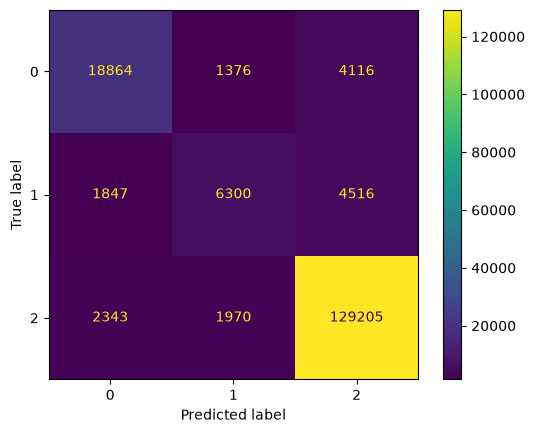

In [39]:
cm=confusion_matrix(ytest,ypred)
print(cm)
cmd=ConfusionMatrixDisplay(cm)
cmd.plot()

In [41]:
print("Accuracy score:",accuracy_score(ytest,ypred))
print("Precision score:",precision_score(ytest,ypred,average='weighted'))
print("Recall score:",recall_score(ytest,ypred,average='weighted'))
print("F1 score:",f1_score(ytest,ypred,average='weighted'))

Accuracy score: 0.9051935943519588
Precision score: 0.8992553266386656
Recall score: 0.9051935943519588
F1 score: 0.9011684575091414


### Classification Report Visualization

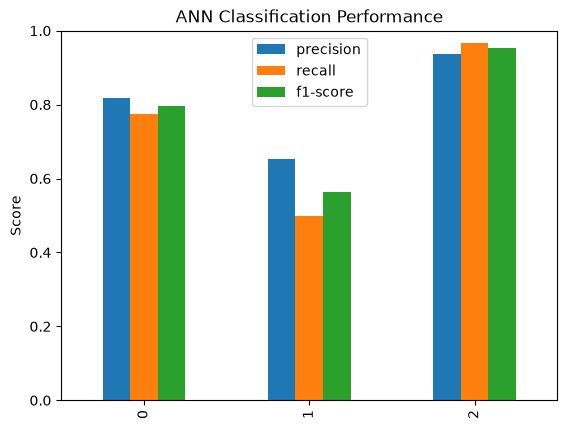

In [42]:
from sklearn.metrics import classification_report
report=classification_report(ytest,ypred,output_dict=True)
df=pd.DataFrame(report).transpose()
df.iloc[:3][['precision','recall','f1-score']].plot(kind='bar')
plt.title('ANN Classification Performance')
plt.ylabel('Score')
plt.ylim(0,1)
plt.show()

#### Actual vs Predicted Sentiment Distribution

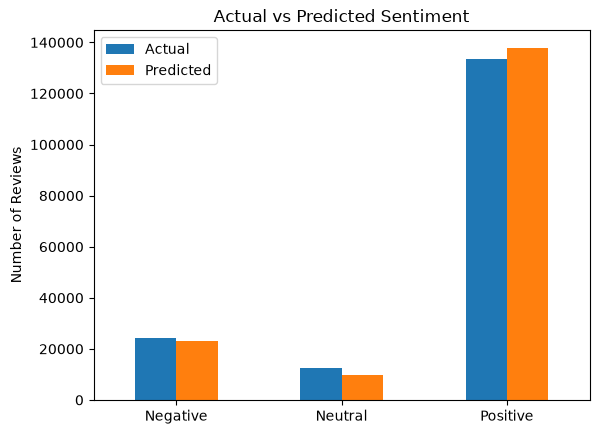

In [ ]:
actual = pd.Series(ytest).value_counts().sort_index()
predicted = pd.Series(ypred).value_counts().sort_index()
df = pd.DataFrame({'Actual': actual,'Predicted': predicted}).fillna(0)
df.index = ['Negative', 'Neutral', 'Positive']
df.plot(kind='bar')
plt.title('Actual vs Predicted Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()